---
numbering: false
---

# Batch Download Landsat Data

Broadly the same as downloading an individual image until it gets to the `odc.stac.load()` stage.

In [1]:
import pystac_client
import planetary_computer
import odc.stac

import geopandas as gpd
import rioxarray as rxr
import numpy as np

import matplotlib.pyplot as plt

from shapely import box
from pystac import ItemCollection

## Use `pystac-client` to search for Landsat data

Set out our search criteria. If you cannot find a suitable image (e.g. your search returns zero items, or those that exist are cloudy) you may have to broaden your search criteria.

In [2]:
# Provide a name for our area of interest (AOI)
aoi_name = "powys"

# Provide the bounding box coordinates for the AOI in the format [min_lon, min_lat, max_lon, max_lat]
bbox = [-3.80182451, 52.23087296, -3.58495919, 52.38308418]

# Provide the date range for the search in the format "YYYY-MM-DD/YYYY-MM-DD"
daterange = "2026-04-20/2026-05-31"  # summer 2026

# Provide a cloud cover percentage threshold for filtering the search results
max_cloud_percent = 20  # maximum cloud cover percentage

# Filter only to scenes where fractional coverage of bounding box exceeds desired threshold
aoi_fraction_threshold = .7  # 70% minimum

# Provide a 'collection' from the Microsoft Planetary Computer STAC API to search for imagery. 
# For example, "landsat-c2-l2" for Landsat Collection 2 Level 2 data.
# See https://planetarycomputer.microsoft.com/CATALOG for more examples
collection = "landsat-c2-l2"

Turn our bbox list into a `GeoPandas` dataframe to sanity check we have the correct region:

In [3]:
aoi = gpd.GeoDataFrame(geometry=[box(*bbox)], crs="EPSG:4326")

aoi.explore()

Connect the Microsoft Planetary Computer.

In [4]:
# Connect to the MPC
stac_url = "https://planetarycomputer.microsoft.com/api/stac/v1"

catalog = pystac_client.Client.open(
    stac_url,
    modifier=planetary_computer.sign_inplace,  # only needed for MPC

    )

Search for the dataset according to our search parameters. I have included two custom `query` statements which you can comment/uncomment and edit if you like: 

 - Sorted by cloud cover in ascending order.
 - Search for only Landsats 5, 8, and 9 (ignoring 1-4, which are unimportant unless you are looking for pre-1990 data, and 7, which has scanline issues barring between 1999-2001).

In [5]:
# Search for cloud-free Landsat 8/9 Surface Reflectance (c2l2-sr) imagery in Summer
search = catalog.search(
    collections=[collection],
    bbox=bbox,
    datetime=daterange,
    query={
        "eo:cloud_cover": {"lt": max_cloud_percent},  # Cloud cover less than 15%
        "platform": {"in": ["landsat-5", "landsat-8", "landsat-9"]},  # Return only Landsat 5, 8, and 9. 
        }, 
    sortby=[{"field": "properties.eo:cloud_cover", "direction": "asc"}]  # Sort by cloud cover in ascending order
)

# Convert the search result object into a list of `pystac.Item` objects
items = search.item_collection()
print(f"Found {len(items)} matching scene(s).")

Found 5 matching scene(s).


The next cell is a custom script that filters out satellite scenes that only clip the area of interest by a small fraction. The minimum fraction you would like is set by `bbox_fraction_threshold` above (defaults to `0.7`, i.e. 70%).

In [6]:
# convert aoi to a geopandas dataframe
aoi_gdf = gpd.GeoDataFrame(geometry=[box(*bbox)], crs="EPSG:4326")

# convert search results to a geopandas dataframe
search_gdf = gpd.GeoDataFrame.from_features(items.to_dict(), crs="EPSG:4326")

# convert both to an equal area projection (EPSG:8857) so we can work in metres
aoi_gdf = aoi_gdf.to_crs(8857)
search_gdf = search_gdf.to_crs(8857)

# clip search gdf to aoi gdf
search_gdf = search_gdf.clip(aoi_gdf)

# Calculate the fraction of the AOI covered by each scene
search_gdf = search_gdf.sort_index()
search_gdf["frac"] = search_gdf.area / aoi_gdf.area.values[0]

# Include a boolean column indicating whether the scene exceeds the AOI fraction threshold
search_gdf["exceed_frac"] = np.where(search_gdf["frac"].values >= aoi_fraction_threshold, True, False)

# Reconstruct the ItemCollection with only the items that exceed the AOI fraction threshold
items_list = []
for i, exceed_frac in zip(items, search_gdf.exceed_frac.values):
    if exceed_frac == True:
        items_list.append(i)

items = ItemCollection(items=items_list)
print(f"Afer AOI filtering, returns {len(items)} Items")

Afer AOI filtering, returns 5 Items


If you cannot find any items after searching, you may have to broaden your search parameters.

## Downloading batch data with `odc-stac`

Load all requested Landsat data as a data cube using `odc.stac.load()`. Note the following changes:

 - I supply the entire `items` list to the STAC, not just a single `[item]`. This produces a final `dataset` of all images, seperated along a `time` dimension (hey, look - this is now what I would call a _datacube_ rather than a _raster_).
 - Rather than extracting properties manually, I include a `with_properties` parameter in the `load` function, which will include the platform and scene ID as additional relevant variables. This will help us construct relevant filenames for each scene.

In [33]:
# Requested bands - I've commented out some we don't need for now, but you can uncomment them if you want to use them later
bands = [
    # 'coastal',  # band 1, coastal/aerosol
    'blue',  # band 2, blue
    'green',  # band 3, green
    'red',  # band 4, red
    'nir08',  # band 5, near-infrared
    'swir16',  # band 6, shortwave infrared 1
    'swir22',  # band 7, shortwave infrared 2
]

# Load requested bands directly into an xarray.Dataset using odc-stac
ds = odc.stac.load(
    items,  # provide the list of items to load
    bands=bands,
    bbox=bbox,
    # crs="EPSG:XXXX",  # Uncomment if you want a different projection: by default, will use the native UTM zone CRS
    # resolution=100, # Uncomment if you want a different resolution: by default, will use the native resolution of the imagery
    with_properties=[
        {"key": "platform", "dtype": "str"},
        {"key": "landsat:scene_id", "dtype": "str"},
    ]
).squeeze()

# Change 'platform' and 'landsat:scene_id' from variables to coordinates
ds = ds.set_coords(["platform", "landsat_scene_id"])

# xarray is 'lazy' by default, meaning it doesn't (down)load the data into memory until you explicitly ask for it.
# The `.compute()` method forces the data to be loaded into memory, which can take some time depending on the size of the dataset.
ds = ds.compute()

ds

<xarray.Dataset> Size: 17MB
Dimensions:           (y: 570, x: 500, time: 5)
Coordinates:
  * y                 (y) float64 5kB 5.804e+06 5.804e+06 ... 5.787e+06
  * x                 (x) float64 4kB 4.452e+05 4.453e+05 ... 4.602e+05
  * time              (time) datetime64[ns] 40B 2026-04-22T11:04:31.047035 .....
    platform          (time) <U9 180B 'landsat-9' 'landsat-9' ... 'landsat-9'
    landsat_scene_id  (time) <U21 420B 'LC92030242026112LGN00' ... 'LC9203024...
    spatial_ref       int32 4B 32630
Data variables:
    blue              (time, y, x) uint16 3MB 7933 7942 8107 ... 9079 9098 8918
    green             (time, y, x) uint16 3MB 8604 8661 8752 ... 10561 10217
    red               (time, y, x) uint16 3MB 8374 8436 8627 ... 10813 10479
    nir08             (time, y, x) uint16 3MB 16820 16313 15547 ... 20936 20413
    swir16            (time, y, x) uint16 3MB 11425 11947 11745 ... 17799 17065
    swir22            (time, y, x) uint16 3MB 9232 9487 9780 ... 12947 12636

Same preprocessing steps: apply a `band` dimension and add appropriate attribute names. Also, convert to fix `NaN` values and convert to surface refelctance.

In [34]:
# stack variables into a band dimension
ds = ds.to_array(dim="band").squeeze()

# add the band names as a long_name attribute to the dataset
ds.attrs["long_name"] = list(ds["band"].values)

# set zero to NaN
ds = ds.where(ds > 0)

# Surface reflectance scaling values
ds = ds * 0.0000275 - 0.2  # convert to SR

# Visualise
ds

<xarray.DataArray (band: 6, time: 5, y: 570, x: 500)> Size: 34MB
array([[[[0.0181575 , 0.01840501, 0.0229425 , ..., 0.0442275 ,
          0.04378749, 0.04356749],
         [0.020165  , 0.02112749, 0.0229975 , ..., 0.044475  ,
          0.0451625 , 0.04290751],
         [0.02209   , 0.0221725 , 0.0287175 , ..., 0.04274251,
          0.0399375 , 0.0421375 ],
         ...,
         [0.03111   , 0.03204499, 0.02720501, ..., 0.07285501,
          0.06240501, 0.0505525 ],
         [0.0329525 , 0.030725  , 0.0317425 , ..., 0.07359751,
          0.07169999, 0.05462249],
         [0.03600501, 0.03443749, 0.0372425 , ..., 0.06958251,
          0.06930749, 0.05643751]],

        [[0.0158475 , 0.0190925 , 0.01835001, ..., 0.03839751,
          0.03737999, 0.0371875 ],
         [0.0179375 , 0.016535  , 0.0182675 , ..., 0.039635  ,
          0.03845251, 0.0358675 ],
         [0.01895499, 0.0160125 , 0.02552749, ..., 0.0371875 ,
          0.0336675 , 0.03507   ],
...
          0.1762275 , 0.1564825 ],
         [0.096725  , 0.103985  , 0.09177499, ..., 0.1947075 ,
          0.1953675 , 0.15945251],
         [0.1017025 , 0.11622249, 0.11809249, ..., 0.19151749,
          0.1900325 , 0.17138751]],

        [[       nan,        nan,        nan, ..., 0.10283001,
          0.10074   , 0.09826501],
         [       nan,        nan,        nan, ..., 0.0994475 ,
          0.10071249, 0.09892501],
         [       nan,        nan,        nan, ..., 0.10101499,
          0.09680749, 0.10041   ],
         ...,
         [0.0907575 , 0.10230751, 0.0838825 , ..., 0.16805999,
          0.1533475 , 0.14273249],
         [0.09438749, 0.09969501, 0.09425001, ..., 0.158655  ,
          0.1629725 , 0.1417975 ],
         [0.09950249, 0.10731249, 0.10822   , ..., 0.155795  ,
          0.1560425 , 0.14749001]]]],
      shape=(6, 5, 570, 500), dtype=float32)
Coordinates:
  * band              (band) object 48B 'blue' 'green' ... 'swir16' 'swir22'
  * time              (time) datetime64[ns] 40B 2026-04-22T11:04:31.047035 .....
    platform          (time) <U9 180B 'landsat-9' 'landsat-9' ... 'landsat-9'
    landsat_scene_id  (time) <U21 420B 'LC92030242026112LGN00' ... 'LC9203024...
  * y                 (y) float64 5kB 5.804e+06 5.804e+06 ... 5.787e+06
  * x                 (x) float64 4kB 4.452e+05 4.453e+05 ... 4.602e+05
    spatial_ref       int32 4B 32630
Attributes:
    long_name:  ['blue', 'green', 'red', 'nir08', 'swir16', 'swir22']

We can loop through the `time` dimension to check the image has good coverage and quality.

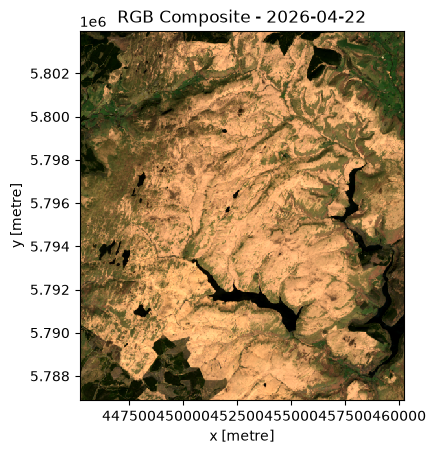

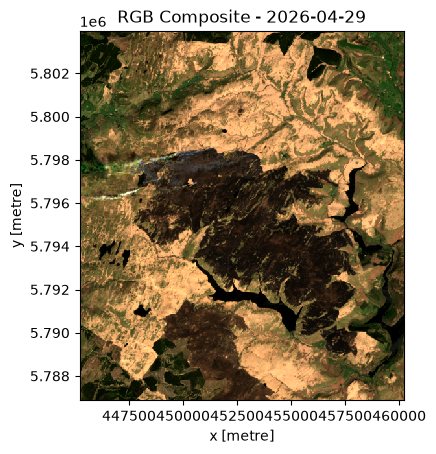

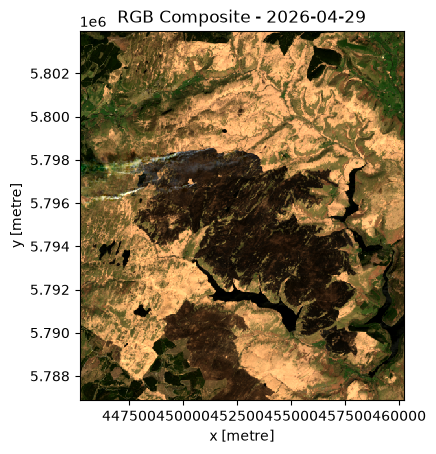

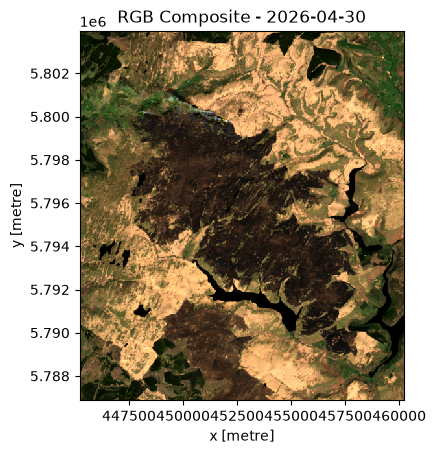

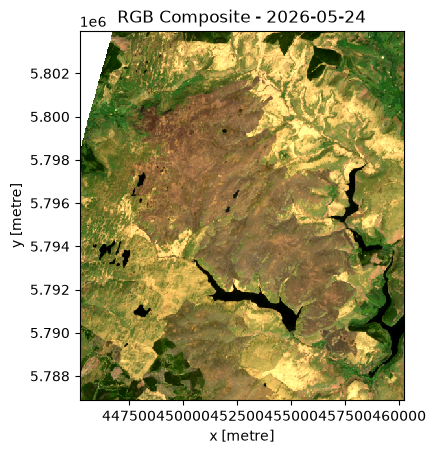

In [35]:
# Loop through each time step in the dataset and plot the RGB composite for each one
for i in range(ds.sizes["time"]):

    # generate an RGB composite for the current time step
    rgb = ds.sel(band=["red", "green", "blue"]).isel(time=i)

    # extract the date string from the time coordinate
    date_str = str(rgb["time"].values)[:10] 

    # Plot the RGB composite 
    fig, ax = plt.subplots()
    rgb.plot.imshow(ax=ax, robust=True)
    ax.set_aspect("equal")
    ax.set_title(f"RGB Composite - {date_str}")
    plt.show()

 You can always delete specific images from the stack by index number if one isn't any good or useful using `drop`. We have two nearly identical images (taken less than hour apart) for 2026-04-29, so we will drop the first one here: 

In [37]:
# drop the dataarray at time index 1
ds = ds.drop_isel(time=1)

Now we through and save these under a sensible name, auto-generated from parameters.

I have chosen a slightly different naming convention here, including (i) the set AOI name; (ii) the date, and (iii) the full scene ID. Having the AOI name and data first allows the filenames to be ordered alphebetically in a sensible order. Including the full scene ID allows for multiple scenes taken on the same day to be recorded (e.g. if Landsat 8 and 9 satellite passed over the same location on the same day, not uncommon at higher latitudes where orbital paths begin to overlap).

In [40]:
import os

# Construct a directory name using the AOI name
directory = f"{aoi_name}_data"

# Create the directory if it doesn't exist
if not os.path.exists(directory):
    os.makedirs(directory)

# Loop through each time step in the dataset
for i in range(len(ds.time)):

    # Select the i-th time step and squeeze the time dimension
    ds_sel = ds.isel(time=i).squeeze()

    # Get the date of the selected time step and format it as a string
    date = ds_sel.time.values.astype("datetime64[D]").astype(str)

    # Get the satellite from the 'platform' coordinate of the selected time step
    satellite = ds_sel.platform.values

    # Get the scene ID from the 'landsat_scene_id' coordinate of the selected time step
    scene_id = ds_sel.landsat_scene_id.values

    # Construct filename using the AOI name, satellite, and date
    filename = f"{aoi_name}_{date}_{scene_id}.tif"

    # Construct the full path to save the file in the specified directory
    filepath = os.path.join(directory, filename)

    print(f"Saving {filepath}...")

    # Save the selected time step as a GeoTIFF file
    ds_sel.rio.to_raster(filepath, compress="deflate", dtype="float32")

Saving powys_data/powys_2026-04-22_LC92030242026112LGN00.tif...
Saving powys_data/powys_2026-04-29_LC92040242026119LGN00.tif...
Saving powys_data/powys_2026-04-30_LC82030242026120LGN00.tif...
Saving powys_data/powys_2026-05-24_LC92030242026144LGN00.tif...


Note the slightly different convention of scene ID here than from the USGS EarthExplorer, using a compressed shorthand. For instance, for `LC92040232026119LGN00`:

 - `L`: Landsat
 - `C`: Combined OLI and TIRS sensors.
 - `9`: Landsat 9
 - `204`: Path
 - `023`: Row
 - `2026`: Acquisition year (2026)
 - `119`: Day of year (DoY) (29th April).
 - `LGN`: Ground station identifier.
 - `00`: Scene archive version 00.